# PINN modeling: physics-informed neural networks for post-meal glucose

**Where we are.** `Modeling_1` fitted a small physics model (four ODEs, three numbers per person). Its clearance parameter tracked HbA1c well, but prediction was only about as good as a simple baseline, peak timing was poor, and T2D was hard. The main suspects: every meal of a person was absorbed at the same speed, logged carbs were taken at face value, and glucose always had to return to its starting value.

**What a PINN is, in plain terms.** A neural network is flexible but knows nothing about the body; a physics model knows the body but is rigid. A *physics-informed* neural network combines them: the network learns from data, and the physics keeps what it learns realistic. There are two common ways to do this, and this notebook builds both:

| | Part A: classic PINN | Part B: hybrid physics–neural model |
|---|---|---|
| What the network does | Draws the whole glucose curve over time | Sets a few physical quantities for each meal |
| How physics enters | Training penalizes curves that break the ODEs | The ODEs themselves produce the curve |
| Good for | Understanding the method; problems without a fast solver | Many meals, fast prediction, interpretable outputs |

Part B is the main model. Part A shows the textbook method on one meal and explains why we don't use it for the full dataset.

**Plan**
1. Load the same meals and the same train/test split as `Modeling_1`, plus a **validation** slice taken from the training meals. Every modeling choice is made on validation meals; the test meals are used once, at the end.
2. **Part A:** a classic PINN on a synthetic meal (known answer), the effect of the physics weight, and one real meal.
3. **Part B:** build the hybrid model step by step, choose the version on validation meals, test it against `Modeling_1` and the baselines with confidence intervals, look at what the network learned, test it on brand-new people, and check its parameters against HbA1c.

**Requirements:** PyTorch (CPU is enough; there's an optional GPU switch in the setup cell) plus numpy, pandas, scipy and matplotlib. Reads the `processed/` files from `EDA.ipynb` and `Modeling_1.ipynb`. A full run takes roughly 5–10 minutes on a laptop CPU.

## 0. Setup

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.stats import spearmanr

try:
    import torch
    import torch.nn as nn
except ImportError as e:
    raise ImportError("PyTorch is needed for this notebook. Install it with:  pip install torch  (the CPU version is enough)") from e

DATA_DIR = Path.cwd()
P = DATA_DIR / "processed"
assert (P / "model1_params.csv").exists(), "Run EDA.ipynb and Modeling_1.ipynb first: they create the files in processed/."

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(max(1, torch.get_num_threads()))

# GPU switch for the hybrid model (Part B). The classic PINN in Part A always runs on the CPU.
# The hybrid simulates many small meal curves step by step, so a GPU may not be faster here; time both if curious.
# A GPU needs the CUDA build of PyTorch (pip's default install on Windows is CPU-only).
USE_GPU = False
DEVICE = torch.device("cuda" if USE_GPU and torch.cuda.is_available() else "cpu")
if USE_GPU and DEVICE.type == "cpu":
    print("USE_GPU is True but PyTorch can't see a CUDA GPU, so the CPU will be used.")
print("PyTorch", torch.__version__, "| CPU threads:", torch.get_num_threads(), "| hybrid model runs on:",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

GRID = np.arange(0, 181, 5)          # minutes after meal start (Dexcom every 5 minutes)
P2 = 0.025                           # insulin-action speed, fixed as in Modeling_1
GROUP_ORDER = ["Healthy", "Prediabetes", "T2D"]
GROUP_COLORS = {"Healthy": "#2a78d6", "Prediabetes": "#eb6834", "T2D": "#1baf7a"}
C_MEASURED, C_HYBRID, C_ODE, C_BASE = "0.55", "#2a78d6", "#eb6834", "#9aa0a6"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlesize": 12})

PyTorch 2.15.0+cu132 | CPU threads: 2 | hybrid model runs on: CPU


## 1. Data: the same meals as `Modeling_1`, plus a validation slice

Same isolated meals (at least 5 g carbs, at least 80% of the 3-hour Dexcom curve observed) and the same time-ordered split: each person's first 70% of meals for training, last 30% for testing.

**New here:** the last 20% of each person's *training* meals become a **validation** set. We use it to stop training at the right moment and to choose between model versions, so the test meals stay untouched until the final comparison. (This avoids the problem we flagged in `Modeling_1`: picking whichever version happens to score best on the test meals makes that score look better than it really is.)

We also compute the pre-meal information from `Modeling_1` section 6: how much glucose changed in the hour before eating, and how far it was above the person's resting (overnight) level.

In [2]:
dex = pd.read_csv(P / "dexcom_5min.csv", parse_dates=["timestamp"])
resp = pd.read_csv(P / "meal_responses.csv", parse_dates=["timestamp"])
parts = pd.read_csv(P / "participants.csv")
flags = pd.read_csv(P / "participant_flags.csv").set_index("sid")
m1_params = pd.read_csv(P / "model1_params.csv").set_index("sid")
series = {sid: g.set_index("timestamp")["glucose"] for sid, g in dex.groupby("sid")}

def meal_curve(sid, t0):
    g = series[sid][t0 - pd.Timedelta("20min"): t0 + pd.Timedelta("185min")].dropna()
    rel = (g.index - t0).total_seconds() / 60
    return np.interp(GRID, rel, g.values, left=np.nan, right=np.nan)

meals = resp[resp.carbs >= 5].copy()
meals["obs"] = [meal_curve(r.sid, r.timestamp) for r in meals.itertuples()]
meals = meals[[np.isnan(o).mean() < 0.2 for o in meals.obs]].copy()
meals["Gb"] = meals["baseline"]
bw_kg = parts.set_index("sid")["weight_lb"] * 0.4536
meals["alpha"] = meals.sid.map(1000 * 0.9 / (1.88 * bw_kg))

# Same train/test split as Modeling_1
meals = meals.sort_values(["sid", "timestamp"])
meals["order"] = meals.groupby("sid").cumcount()
meals["n_meals"] = meals.groupby("sid")["sid"].transform("size")
meals["split"] = np.where(meals["order"] < np.ceil(0.7 * meals["n_meals"]), "train", "test")
meals = meals[meals.groupby("sid")["split"].transform(lambda s: (s == "test").sum() >= 1 and (s == "train").sum() >= 4)]

# Validation: the last 20% of each person's training meals
is_tr = meals.split == "train"
meals["tr_order"] = meals[is_tr].groupby("sid").cumcount()
meals["n_tr"] = meals[is_tr].groupby("sid")["sid"].transform("size")
meals.loc[is_tr & (meals.tr_order >= np.floor(0.8 * meals.n_tr)), "split"] = "val"

# Pre-meal information (known before eating), as in Modeling_1 section 6
def glucose_near(sid, t, window="10min"):
    g = series[sid][t - pd.Timedelta(window): t + pd.Timedelta(window)].dropna()
    return g.mean() if len(g) else np.nan

meals["pre_change_60"] = meals["Gb"] - [glucose_near(r.sid, r.timestamp - pd.Timedelta("60min")) for r in meals.itertuples()]
first_test = meals[meals.split == "test"].groupby("sid")["timestamp"].min()
def resting_level(sid):
    g = series[sid]
    g = g[(g.index < first_test[sid]) & (g.index.hour >= 2) & (g.index.hour < 5)]
    return g.median()
meals["resting"] = meals.sid.map({s: resting_level(s) for s in meals.sid.unique()})
meals["above_resting"] = meals["Gb"] - meals["resting"]
meals["clean"] = (meals["pre_change_60"].abs() <= 15) & (meals["above_resting"] <= 30)
meals["hour"] = meals.timestamp.dt.hour + meals.timestamp.dt.minute / 60
meals = meals.reset_index(drop=True)

train, val, test = (meals[meals.split == k] for k in ["train", "val", "test"])
print(f"{len(meals)} meals from {meals.sid.nunique()} people | train {len(train)}, validation {len(val)}, test {len(test)}")
meals.groupby(["group", "split"]).size().unstack().reindex(GROUP_ORDER)

831 meals from 36 people | train 463, validation 134, test 234


split,test,train,val
group,,,
Healthy,74,145,42
Prediabetes,75,152,44
T2D,85,166,48


A plain ODE solver from `Modeling_1`, reused here to reproduce its predictions and to make synthetic data. It steps the four equations forward one minute at a time with Heun's method.

In [3]:
def simulate_np(ka, SG, SI, carbs, Gb, alpha, s=None):
    carbs = np.atleast_1d(np.asarray(carbs, float)); n = len(carbs)
    Gb = np.broadcast_to(np.asarray(Gb, float), (n,)).copy()
    s = np.ones(n) if s is None else s
    G, X, Q1, Q2 = Gb.copy(), np.zeros(n), carbs * s, np.zeros(n)
    out = [G]
    def rates(G, X, Q1, Q2):
        exc = G - Gb
        return (-(SG + X) * exc + alpha * ka * Q2, -P2 * X + P2 * SI * np.maximum(exc, 0), -ka * Q1, ka * Q1 - ka * Q2)
    for step in range(1, 181):
        a = rates(G, X, Q1, Q2); b = rates(G + a[0], X + a[1], Q1 + a[2], Q2 + a[3])
        G, X, Q1, Q2 = G + (a[0] + b[0]) / 2, X + (a[1] + b[1]) / 2, Q1 + (a[2] + b[2]) / 2, Q2 + (a[3] + b[3]) / 2
        if step % 5 == 0: out.append(G)
    return np.stack(out, 1)

# Part A: a classic PINN

## 2. The idea

A classic PINN uses a neural network as a **flexible curve-drawer**. You give it a time *t*, and it returns the four quantities of our model at that time: glucose G, insulin action X, and carbs in the stomach Q1 and gut Q2.

Training pushes on it from two sides at once:

1. **Match the measurements:** at the Dexcom times, the network's G should be close to the readings.
2. **Obey the physics:** at many time points (every minute here), the network's curves must satisfy the four ODEs. Automatic differentiation gives the exact slope of each curve, so we can measure how badly each equation is broken: the **residual**, slope the network drew minus slope the physics demands.

```
loss = (data mismatch) + λ × (physics residual)
```

The unknown parameters ka, SG and SI are learned **alongside** the network. They only enter through the physics term, so the physics is what lets the data reveal them. That's why a PINN can solve an "inverse problem": infer hidden parameters from partial measurements.

**Built-in starting values.** Rather than adding another penalty for the starting conditions, we write the outputs so they *must* start right: for example G = Gb + τ × (network output), with τ = t/180, so at t = 0 glucose is exactly the pre-meal level. Q1 starts at the logged carbs and only decreases; Q2 and X start at 0.

**λ (the physics weight)** sets how strictly the network must obey the equations. Too small, and it just traces the noisy data and the parameters are poorly determined. Too large, and it obeys the equations but may stop fitting the data while training. Section 4 shows this.

In [4]:
class ClassicPINN(nn.Module):
    def __init__(self, carbs, Gb, alpha, hidden=48, init=(0.02, 0.02, 3e-4)):
        super().__init__()
        self.carbs, self.Gb, self.alpha = float(carbs), float(Gb), float(alpha)
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(),
                                 nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 4))
        self.logp = nn.Parameter(torch.tensor(np.log(init), dtype=torch.float32))   # log ka, log SG, log SI

    def states(self, t):                                  # t: minutes, shape (n, 1)
        tau = t / 180.0
        u = self.net(tau)
        sp = nn.functional.softplus
        G = self.Gb + 100.0 * tau * u[:, :1]                                  # starts at Gb
        X = 0.01 * tau * u[:, 1:2]                                            # starts at 0
        Q1 = self.carbs * torch.exp(-3.0 * tau * sp(u[:, 2:3]))               # starts at carbs, only decreases
        Q2 = self.carbs * tau * sp(u[:, 3:4])                                 # starts at 0, never negative
        return G, X, Q1, Q2

    def residuals(self, t):
        t = t.requires_grad_(True)
        G, X, Q1, Q2 = self.states(t)
        slope = lambda y: torch.autograd.grad(y, t, torch.ones_like(y), create_graph=True)[0]
        ka, SG, SI = torch.exp(self.logp)
        exc = G - self.Gb
        rG = slope(G) - (-(SG + X) * exc + self.alpha * ka * Q2)
        rX = slope(X) - (-P2 * X + P2 * SI * torch.relu(exc))
        r1 = slope(Q1) - (-ka * Q1)
        r2 = slope(Q2) - (ka * Q1 - ka * Q2)
        # scale each equation so all four count roughly equally
        return torch.cat([rG, rX / 1e-4, r1 / (0.02 * self.carbs), r2 / (0.02 * self.carbs)], 1)

def train_classic(t_obs, g_obs, carbs, Gb, alpha, iters=6000, lam=1.0, seed=SEED, log_every=1500):
    torch.manual_seed(seed)
    m = ClassicPINN(carbs, Gb, alpha)
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.StepLR(opt, 2000, 0.5)
    t_obs = torch.tensor(t_obs, dtype=torch.float32)[:, None]
    g_obs = torch.tensor(g_obs, dtype=torch.float32)[:, None]
    keep = ~torch.isnan(g_obs)
    t_col = torch.linspace(0, 180, 181)[:, None]           # physics checked every minute
    hist, t0 = [], time.time()
    for it in range(iters):
        opt.zero_grad()
        G = m.states(t_obs)[0]
        data = ((G - g_obs)[keep] ** 2).mean()
        phys = (m.residuals(t_col.clone()) ** 2).mean()
        (data + lam * phys).backward(); opt.step(); sched.step()
        if it % 50 == 0:
            hist.append((it, data.item(), phys.item(), *torch.exp(m.logp).tolist()))
        if log_every and it % log_every == 0:
            print(f"  iter {it:5d}: data RMSE {data.item() ** .5:6.2f} mg/dL | physics residual {phys.item():.4f} | {time.time() - t0:.0f}s")
    return m, pd.DataFrame(hist, columns=["iter", "data_mse", "physics", "ka", "SG", "SI"]), time.time() - t0

def pinn_curve(m, t=GRID):
    with torch.no_grad():
        return m.states(torch.tensor(t, dtype=torch.float32)[:, None])[0].numpy().ravel()

## 3. Test on a synthetic meal (known answer)

We simulate one 60 g carb meal for a made-up person with known parameters, add 3 mg/dL of measurement noise, and ask the PINN to recover the parameters from the noisy readings. For comparison, we also fit the same readings directly with the ODE solver and `least_squares`, as in `Modeling_1`.

In [5]:
TRUE = dict(ka=0.025, SG=0.015, SI=4e-4)
carbs_s, Gb_s, alpha_s = 60.0, 100.0, 6.0
rng = np.random.default_rng(1)
clean_curve = simulate_np(TRUE["ka"], TRUE["SG"], TRUE["SI"], carbs_s, Gb_s, alpha_s)[0]
noisy = clean_curve + rng.normal(0, 3, len(GRID))

print("Training the classic PINN on one synthetic meal...")
pinn_s, hist_s, secs_pinn = train_classic(GRID.astype(float), noisy, carbs_s, Gb_s, alpha_s, iters=6000, lam=1.0)

t0 = time.time()
direct = least_squares(lambda x: simulate_np(*np.exp(x), carbs_s, Gb_s, alpha_s)[0] - noisy,
                       np.log([0.02, 0.02, 3e-4]), bounds=(np.log([0.003, 5e-4, 1e-6]), np.log([0.2, 0.15, 5e-3])))
secs_direct = time.time() - t0
direct_p = np.exp(direct.x)

comparison = pd.DataFrame({
    "true": [TRUE["ka"], TRUE["SG"], TRUE["SI"], 0.0, np.nan],
    "classic PINN": [*torch.exp(pinn_s.logp).tolist(), np.sqrt(np.mean((pinn_curve(pinn_s) - clean_curve) ** 2)), secs_pinn],
    "direct ODE fit": [*direct_p, np.sqrt(np.mean((simulate_np(*direct_p, carbs_s, Gb_s, alpha_s)[0] - clean_curve) ** 2)), secs_direct],
}, index=["ka", "SG", "SI", "curve error vs truth (mg/dL)", "time (s)"])
comparison

Training the classic PINN on one synthetic meal...


  iter     0: data RMSE  49.24 mg/dL | physics residual 2.1256 | 0s


  iter  1500: data RMSE   2.65 mg/dL | physics residual 0.0165 | 6s


  iter  3000: data RMSE   2.60 mg/dL | physics residual 0.0075 | 13s


  iter  4500: data RMSE   2.55 mg/dL | physics residual 0.0061 | 19s


,true,classic PINN,direct ODE fit
ka,0.0250,0.026044,0.024430
SG,0.0150,0.023093,0.011376
SI,0.0004,0.000180,0.000472
curve error vs truth (mg/dL),0.0000,0.987112,0.586543
time (s),NaN,24.964307,0.119236


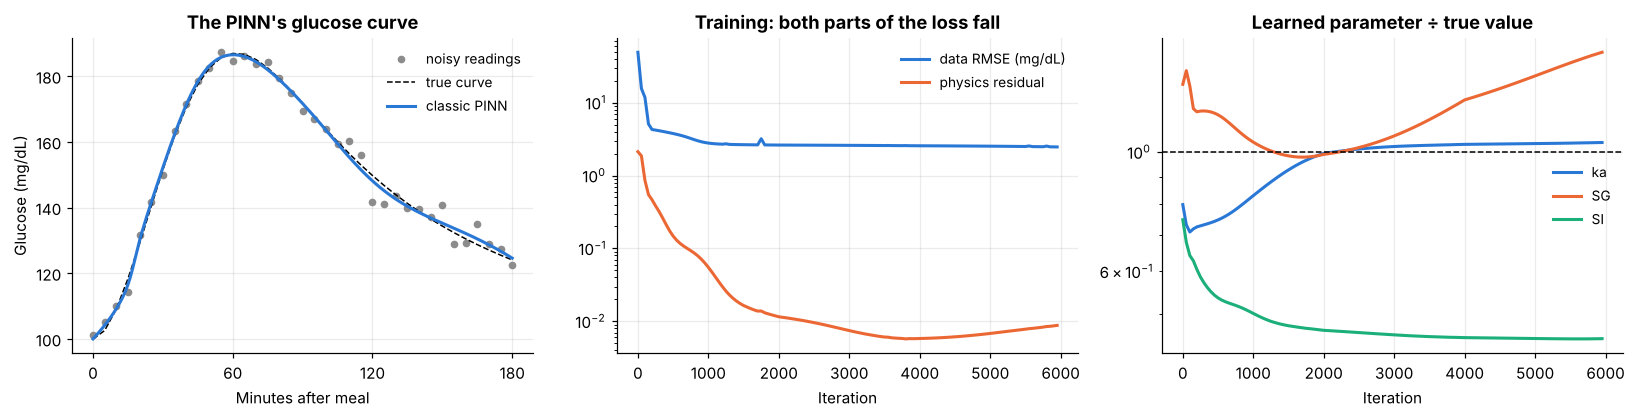

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].plot(GRID, noisy, "o", color=C_MEASURED, ms=4, label="noisy readings")
axes[0].plot(GRID, clean_curve, color="black", lw=1, ls="--", label="true curve")
tt = np.linspace(0, 180, 181)
axes[0].plot(tt, pinn_curve(pinn_s, tt), color=C_HYBRID, label="classic PINN")
axes[0].set(title="The PINN's glucose curve", xlabel="Minutes after meal", ylabel="Glucose (mg/dL)", xticks=range(0, 181, 60))
axes[0].legend(frameon=False, fontsize=9)

axes[1].semilogy(hist_s.iter, hist_s.data_mse ** 0.5, color=C_HYBRID, label="data RMSE (mg/dL)")
axes[1].semilogy(hist_s.iter, hist_s.physics, color=C_ODE, label="physics residual")
axes[1].set(title="Training: both parts of the loss fall", xlabel="Iteration")
axes[1].legend(frameon=False, fontsize=9)

for p, c in zip(["ka", "SG", "SI"], [C_HYBRID, C_ODE, "#1baf7a"]):
    axes[2].plot(hist_s.iter, hist_s[p] / TRUE[p], color=c, label=p)
axes[2].axhline(1, color="black", lw=1, ls="--")
axes[2].set(title="Learned parameter ÷ true value", xlabel="Iteration", yscale="log")
axes[2].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**Reading this:**
- **Left:** the PINN's curve passes through the noisy readings and stays close to the true curve. It never saw the true curve; the physics term kept it smooth and realistic.
- **Middle:** the data error falls to about the noise level (3 mg/dL; it can't go lower without fitting the noise), while the physics residual drops by more than 100×: the network's curves increasingly obey the ODEs.
- **Right:** absorption speed (ka) settles near its true value. **SG and SI trade off against each other:** from one meal, "a bigger always-open drain" and "a bigger insulin drain" produce almost the same curve, so the data can't tell them apart. The direct ODE fit has the same problem, just in a different direction. This is the identifiability issue from `Modeling_1` again, and it's a property of the data, not of the method.
- **Time:** the PINN took tens of seconds for one meal; the direct fit took a fraction of a second.

## 4. The physics weight λ

Same synthetic meal, three values of λ, shorter training. Watch how the balance between fitting the data and obeying the physics changes.

In [7]:
rows = []
for lam in [0.01, 1.0, 100.0]:
    print(f"λ = {lam}")
    m_l, h_l, s_l = train_classic(GRID.astype(float), noisy, carbs_s, Gb_s, alpha_s, iters=2500, lam=lam, log_every=0)
    ka, SG, SI = torch.exp(m_l.logp).tolist()
    rows.append({"λ": lam, "data RMSE (mg/dL)": h_l.data_mse.iloc[-1] ** 0.5, "physics residual": h_l.physics.iloc[-1],
                 "curve error vs truth": np.sqrt(np.mean((pinn_curve(m_l) - clean_curve) ** 2)),
                 "ka / true": ka / TRUE["ka"], "SG / true": SG / TRUE["SG"], "SI / true": SI / TRUE["SI"]})
pd.DataFrame(rows).set_index("λ").round(3)

λ = 0.01


λ = 1.0


λ = 100.0


,data RMSE (mg/dL),physics residual,curve error vs truth,ka / true,SG / true,SI / true
λ,,,,,,
0.01,2.617,0.013,0.842,1.020,0.985,0.442
1.00,2.612,0.010,0.839,1.013,1.019,0.462
100.00,2.506,0.004,1.014,1.018,1.230,0.612


**Reading this:** on this clean synthetic meal, λ matters less than you might expect. Across a 10,000× range, the data fit and the absorption speed stay essentially the same. Two reasons: the starting conditions are built into the network, and the data and the physics *agree* here, since the readings really were produced by these equations.

What λ does change is **how the clearance is split**. Raising it pushes more of the clearance into SG and less into SI. That's the SG–SI trade-off again: when two parameters explain the data equally well, small choices in the loss decide where you land.

λ matters most when data and physics **disagree**, which is exactly what happens on real meals (next section). Choosing λ, and scaling each equation so none dominates, is the main practical difficulty of classic PINNs.

## 5. One real meal

The same classic PINN on a real clean meal from a healthy participant's training data, compared with a direct ODE fit of the same meal.

Participant 27, Dinner, 66 g carbs, starting glucose 111 mg/dL
Training the classic PINN on this meal...
  iter     0: data RMSE  19.76 mg/dL | physics residual 2.6683 | 0s


  iter  1500: data RMSE   2.59 mg/dL | physics residual 0.4829 | 7s


  iter  3000: data RMSE   2.52 mg/dL | physics residual 0.4577 | 13s


  iter  4500: data RMSE   1.81 mg/dL | physics residual 0.4738 | 20s


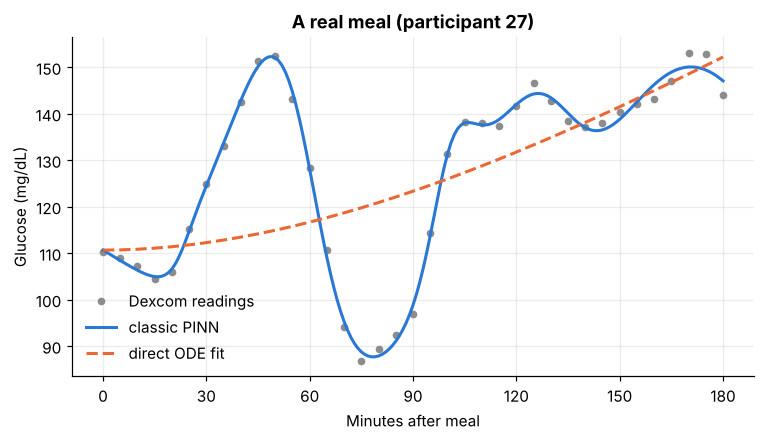

,classic PINN,direct ODE fit
ka,0.023226,0.003082
SG,0.029225,0.000500
SI,0.000121,0.000004


In [8]:
cand = train[(train.group == "Healthy") & train.clean & (train.carbs.between(40, 80))]
real = cand.iloc[len(cand) // 2]
print(f"Participant {real.sid}, {real.meal_type}, {real.carbs:.0f} g carbs, starting glucose {real.Gb:.0f} mg/dL")

print("Training the classic PINN on this meal...")
pinn_r, hist_r, secs_r = train_classic(GRID.astype(float), real.obs, real.carbs, real.Gb, real.alpha, iters=6000, lam=1.0)
keep = ~np.isnan(real.obs)
direct_r = least_squares(lambda x: (simulate_np(*np.exp(x), real.carbs, real.Gb, real.alpha)[0] - real.obs)[keep],
                         np.log([0.02, 0.02, 3e-4]), bounds=(np.log([0.003, 5e-4, 1e-6]), np.log([0.2, 0.15, 5e-3])))
dr = np.exp(direct_r.x)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(GRID, real.obs, "o", color=C_MEASURED, ms=4, label="Dexcom readings")
ax.plot(tt, pinn_curve(pinn_r, tt), color=C_HYBRID, label="classic PINN")
ax.plot(GRID, simulate_np(*dr, real.carbs, real.Gb, real.alpha)[0], color=C_ODE, ls="--", label="direct ODE fit")
ax.set(title=f"A real meal (participant {real.sid})", xlabel="Minutes after meal", ylabel="Glucose (mg/dL)", xticks=range(0, 181, 30))
ax.legend(frameon=False)
plt.show()
pd.DataFrame({"classic PINN": torch.exp(pinn_r.logp).tolist(), "direct ODE fit": dr}, index=["ka", "SG", "SI"])

**Reading this:** this meal passed the clean-meal rule (steady glucose before eating), yet glucose rises, falls well below where it started, then rises again. A second rise like that almost certainly means something else was eaten and not logged.

- The **classic PINN follows every bump** (data error under 2 mg/dL). But look at its physics residual in the training log: it stays around 0.47, roughly **80× higher** than on the synthetic meal. The network is flexible enough to draw the second rise, and with a soft physics penalty it's allowed to break the equations to do so. Its parameters are therefore not meaningful here.
- The **direct ODE fit can't produce a second rise** at all (the equations contain only one meal), so it settles on a slow, steady climb, with parameters pushed to their limits.

This is the core trade-off of physics-informed learning: **a soft physics penalty lets the model explain anything, including things the physics says are impossible.** That's why the physics residual is worth monitoring: a high residual tells you the data contain something your model doesn't.

### Why the main model isn't a classic PINN

The classic PINN works, but for this dataset it has three practical problems:
1. **One network per meal.** Each meal has its own curve, so a classic PINN needs a separate network (or a much more complex one) for each of the ~800 meals, and each takes tens of seconds to train.
2. **It can't predict a new meal without retraining.** The network *is* that meal's curve. To predict tomorrow's lunch you'd have to train again.
3. **We already have a fast, exact solver.** Classic PINNs shine when equations are expensive to solve (for example the partial differential equations in heat flow, as in HVAC modeling). Our four ODEs solve in milliseconds.

So Part B keeps the solver and puts the neural network where it adds the most: deciding the parts of the physics that change from meal to meal.

# Part B: the hybrid physics–neural model

## 6. The idea

Keep `Modeling_1`'s four equations as the backbone, and add a small neural network that looks at **each meal** and sets three things:

| Network output | What it changes | Why |
|---|---|---|
| **Absorption multiplier** (×0.5 to ×2) | how fast this meal is absorbed: ka × multiplier | fat, protein and fiber slow digestion; one speed per person gave poor peak timing |
| **Effective carbs** (×0.5 to ×2) | how much of the logged carbs reaches the blood | carb logs are estimates; `Modeling_1` kept shrinking them during training |
| **Settle fraction** (0 to 1) | where glucose comes back to: from the starting level (0) toward the person's resting level (1) | many meals start while glucose is still elevated, and `Modeling_1` couldn't produce the resulting dips |

**The network's inputs, all known before or at the meal:** log carbs, fat, protein, fiber, time of day, meal type, how much glucose changed in the hour before eating, and how far it starts above the person's resting level. It does **not** see the person's diagnosis, so it can be used for anyone.

**Per person (as in `Modeling_1`):** absorption speed ka, glucose effectiveness SG, insulin sensitivity SI, and (optionally) a personal carb-correction level. These are pulled gently toward a learned population average, the same "borrowing strength" idea as before.

The glucose equation becomes:
```
dG/dt = −(SG + X) × (G − target) + α × ka × multiplier × Q2
target = G0 + settle × (resting − G0)
```
with the stomach starting at logged carbs × effective-carbs factor. Everything is written in PyTorch, so the whole simulation is differentiable: training adjusts the network and the person parameters together, by back-propagating through all 180 one-minute steps.

**Why this still counts as physics-informed:** every prediction is a solution of the ODEs, so it always respects conservation of carbs, clearance toward a target and delayed insulin action. The network can only adjust physical quantities within limits; it can't draw an arbitrary curve. This approach is often called a *universal differential equation* or *differentiable physics* model.

In [9]:
MEAL_TYPES = ["Breakfast", "Lunch", "Dinner", "Snack"]

def meal_features(df):
    f = pd.DataFrame({
        "log_carbs": np.log1p(df.carbs),
        "fat_g": df.fat.fillna(0), "protein_g": df.protein.fillna(0), "fiber_g": df.fiber.fillna(0).clip(upper=60),
        "hour_sin": np.sin(2 * np.pi * df.hour / 24), "hour_cos": np.cos(2 * np.pi * df.hour / 24),
        "pre_change_60": df.pre_change_60.fillna(0).clip(-60, 60), "above_resting": df.above_resting.clip(-60, 120)})
    for t in MEAL_TYPES:
        f["is_" + t.lower()] = (df.meal_type == t).astype(float)
    return f

FEAT_MEAN = meal_features(train).mean()
FEAT_SD = meal_features(train).std().replace(0, 1)
SIDS = sorted(meals.sid.unique()); SID_INDEX = {s: i for i, s in enumerate(SIDS)}

def to_tensors(df):
    F = (meal_features(df) - FEAT_MEAN) / FEAT_SD
    f32 = lambda a: torch.tensor(np.asarray(a, dtype=np.float32), device=DEVICE)
    obs = np.vstack(df.obs.values)
    return dict(idx=torch.tensor(df.sid.map(SID_INDEX).values, device=DEVICE), X=f32(F.values), carbs=f32(df.carbs), G0=f32(df.Gb),
                rest=f32(df.resting), alpha=f32(df.alpha), obs=f32(np.nan_to_num(obs)), mask=f32(~np.isnan(obs)))

D_TRAIN, D_VAL, D_TEST = to_tensors(train), to_tensors(val), to_tensors(test)
print("Network inputs:", list(FEAT_MEAN.index))

Network inputs: ['log_carbs', 'fat_g', 'protein_g', 'fiber_g', 'hour_sin', 'hour_cos', 'pre_change_60', 'above_resting', 'is_breakfast', 'is_lunch', 'is_dinner', 'is_snack']


In [10]:
LOG_BOUNDS = np.log([[0.003, 0.2], [5e-4, 0.15], [1e-6, 5e-3], [0.3, 2.0]])     # ka, SG, SI, personal carb level

class HybridGlucose(nn.Module):
    def __init__(self, init_logp, use_net=True, use_settle=True, person_carbs=False, ka_range=0.7, hidden=32):
        super().__init__()
        init = torch.tensor(np.append(init_logp, 0.0), dtype=torch.float32)
        self.person = nn.Parameter(init.repeat(len(SIDS), 1))        # one row per person: log ka, log SG, log SI, log carb level
        self.pop = nn.Parameter(init.clone())                          # learned population average
        self.use_net, self.use_settle, self.person_carbs, self.ka_range = use_net, use_settle, person_carbs, ka_range
        self.net = nn.Sequential(nn.Linear(len(FEAT_MEAN), hidden), nn.Tanh(),
                                 nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 3))
        nn.init.zeros_(self.net[-1].weight); nn.init.zeros_(self.net[-1].bias)   # start neutral: ×1, ×1 ...
        with torch.no_grad():
            self.net[-1].bias[2] = -2.0                                          # ... and settle fraction ≈ 0.12

    def meal_terms(self, X):
        out = self.net(X); n = len(X); dev = X.device
        ka_mult = torch.exp(self.ka_range * torch.tanh(out[:, 0])) if self.use_net else torch.ones(n, device=dev)
        carb_mult = torch.exp(0.7 * torch.tanh(out[:, 1])) if self.use_net else torch.ones(n, device=dev)
        settle = torch.sigmoid(out[:, 2]) if self.use_settle else torch.zeros(n, device=dev)
        return ka_mult, carb_mult, settle, out

    def forward(self, d, person_logp=None):
        lp = self.person[d["idx"]] if person_logp is None else person_logp
        ka, SG, SI = torch.exp(lp[:, 0]), torch.exp(lp[:, 1]), torch.exp(lp[:, 2])
        ka_mult, carb_mult, settle, raw = self.meal_terms(d["X"])
        if self.person_carbs:
            carb_mult = carb_mult * torch.exp(lp[:, 3])
        ka = ka * ka_mult
        G0, alpha = d["G0"], d["alpha"]
        target = G0 + settle * (d["rest"] - G0)
        G, Xi, Q1, Q2 = G0.clone(), torch.zeros_like(G0), d["carbs"] * carb_mult, torch.zeros_like(G0)
        def rates(G, Xi, Q1, Q2):
            exc = G - target
            return (-(SG + Xi) * exc + alpha * ka * Q2, -P2 * Xi + P2 * SI * torch.relu(exc), -ka * Q1, ka * Q1 - ka * Q2)
        out = [G]
        for step in range(1, 181):                                   # Heun steps, 1 minute each
            a = rates(G, Xi, Q1, Q2); b = rates(G + a[0], Xi + a[1], Q1 + a[2], Q2 + a[3])
            G, Xi, Q1, Q2 = G + (a[0] + b[0]) / 2, Xi + (a[1] + b[1]) / 2, Q1 + (a[2] + b[2]) / 2, Q2 + (a[3] + b[3]) / 2
            if step % 5 == 0:
                out.append(G)
        return torch.stack(out, 1), dict(ka_mult=ka_mult, carb_mult=carb_mult, settle=settle, raw=raw)

def hybrid_loss(model, d, w_person=2.0, w_meal=0.05):
    pred, extra = model(d)
    mse = ((pred - d["obs"]) ** 2 * d["mask"]).sum() / d["mask"].sum()
    used = torch.unique(d["idx"])
    person_prior = (((model.person[used] - model.pop) / 0.5) ** 2).sum(1).mean()   # people pulled toward population
    meal_reg = (extra["raw"][:, :2] ** 2).mean()                                     # meal adjustments pulled toward neutral
    return mse + w_person * person_prior + w_meal * mse.detach() * meal_reg, mse

def train_hybrid(model, d_train, d_val, epochs=300, lr_person=0.03, lr_net=3e-3, label=""):
    opt = torch.optim.Adam([{"params": [model.person, model.pop], "lr": lr_person},
                            {"params": model.net.parameters(), "lr": lr_net, "weight_decay": 1e-4}])
    dev = model.person.device
    lo = torch.tensor(LOG_BOUNDS[:, 0], dtype=torch.float32, device=dev)
    hi = torch.tensor(LOG_BOUNDS[:, 1], dtype=torch.float32, device=dev)
    best, best_state, hist, t0 = np.inf, None, [], time.time()
    for ep in range(epochs):
        opt.zero_grad()
        loss, mse = hybrid_loss(model, d_train)
        loss.backward(); opt.step()
        with torch.no_grad():
            model.person.data = torch.max(torch.min(model.person.data, hi), lo)
            val_mse = hybrid_loss(model, d_val)[1].item()
        hist.append((ep, mse.item() ** 0.5, val_mse ** 0.5))
        if val_mse < best:                                   # early stopping: keep the best validation epoch
            best, best_state = val_mse, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist, columns=["epoch", "train_rmse", "val_rmse"])
    print(f"{label:45s} best validation RMSE {hist.val_rmse.min():5.1f} (epoch {hist.val_rmse.idxmin()}) | {time.time() - t0:.0f}s")
    return hist

## 7. Build it up step by step, and choose on validation meals

Each version adds one idea, so we can see what each contributes. The starting values for every person are `Modeling_1`'s population averages.

| Version | What's added |
|---|---|
| A | physics only: per-person ka, SG, SI (`Modeling_1` rebuilt in PyTorch) |
| B | + settle toward the resting level |
| C | + meal network (absorption speed and effective carbs per meal) |
| D | + personal carb-correction level, and a wider absorption range (×0.37 to ×2.7) |

**Choice rule, decided in advance:** pick the version with the lowest validation RMSE, but if a simpler version is within 0.3 mg/dL of it, pick the simpler one (it's less likely to be overfitting).

In [11]:
INIT_LOGP = np.log(m1_params[["ka", "SG", "SI"]]).median().values
VERSIONS = {
    "A: physics only": dict(use_net=False, use_settle=False),
    "B: + settle toward resting": dict(use_net=False, use_settle=True),
    "C: + meal network": dict(use_net=True, use_settle=True),
    "D: + personal carbs, wider absorption range": dict(use_net=True, use_settle=True, person_carbs=True, ka_range=1.0),
}
models, histories = {}, {}
for name, kw in VERSIONS.items():
    torch.manual_seed(SEED)
    models[name] = HybridGlucose(INIT_LOGP, **kw).to(DEVICE)
    histories[name] = train_hybrid(models[name], D_TRAIN, D_VAL, label=name)

val_table = pd.Series({k: h.val_rmse.min() for k, h in histories.items()}, name="best validation RMSE (mg/dL)")
best_name = val_table.idxmin()
for name in val_table.index:                       # versions are listed simplest first
    if val_table[name] <= val_table.min() + 0.3:
        CHOSEN = name; break
print(f"\nChosen on validation meals: {CHOSEN}")
hybrid = models[CHOSEN]
val_table.round(2).to_frame()

A: physics only                               best validation RMSE  40.2 (epoch 299) | 31s


B: + settle toward resting                    best validation RMSE  34.4 (epoch 299) | 31s


C: + meal network                             best validation RMSE  28.4 (epoch 231) | 31s


D: + personal carbs, wider absorption range   best validation RMSE  28.6 (epoch 176) | 31s

Chosen on validation meals: C: + meal network


,best validation RMSE (mg/dL)
A: physics only,40.19
B: + settle toward resting,34.40
C: + meal network,28.43
"D: + personal carbs, wider absorption range",28.64


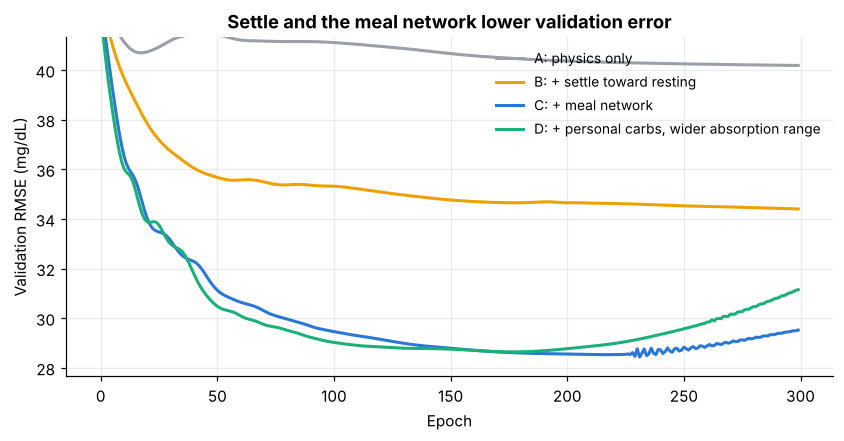

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for (name, h), c in zip(histories.items(), ["#9aa0a6", "#eda100", "#2a78d6", "#1baf7a"]):
    ax.plot(h.epoch, h.val_rmse, color=c, label=name)
ax.set(xlabel="Epoch", ylabel="Validation RMSE (mg/dL)", title="Settle and the meal network lower validation error",
       ylim=(None, np.nanpercentile(histories["A: physics only"].val_rmse, 90)))
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.show()

**Reading this:** settle toward resting (B) and the meal network (C) each lower validation error substantially. D is no better than C, so the simpler C is chosen. C and D both start to **overfit** after about 200 epochs (validation error rises again while training error keeps falling), which is why we keep the best validation epoch rather than the last one.

## 8. Final test: held-out meals

Now, once, the test meals. We compare the chosen hybrid with:
- **`Modeling_1` ODE:** reproduced exactly from its saved parameters (logged carbs, settles at the starting level),
- **A: physics only:** the same physics retrained here, so the comparison isolates what the network and settle term add,
- **the best simple baseline:** each person's average rise per gram of carbs × this meal's carbs (from training and validation meals).

Metrics as before: `rmse` (whole curve), `peak_err` (peak height), `tpeak_err` (peak timing, minutes), and `bias` (positive = predicts too high).

In [13]:
def score_rows(pred, df, name):
    rows = []
    for p, r in zip(pred, df.itertuples()):
        o, q = r.obs - r.Gb, p - r.Gb
        seen = ~np.isnan(o); s0 = seen.copy(); s0[0] = False
        rows.append(dict(sid=r.sid, group=r.group, clean=r.clean, meal_type=r.meal_type, model=name,
                         rmse=np.sqrt(np.mean((q[s0] - o[s0]) ** 2)), peak_err=abs(np.nanmax(q) - np.nanmax(o)),
                         tpeak_err=abs(GRID[np.nanargmax(q)] - GRID[np.nanargmax(o)]), bias=np.mean(q[seen] - o[seen])))
    return rows

def predict(model, d, person_logp=None):
    model.eval()
    with torch.no_grad():
        pred, extra = model(d, person_logp)
    return pred.cpu().numpy(), {k: v.cpu().numpy() for k, v in extra.items()}

pred_hybrid, extra_test = predict(hybrid, D_TEST)
pred_A, _ = predict(models["A: physics only"], D_TEST)
pred_m1 = np.vstack([simulate_np(*m1_params.loc[r.sid, ["ka", "SG", "SI"]], r.carbs, r.Gb, r.alpha)[0] for r in test.itertuples()])
fit_meals = meals[meals.split != "test"]
per_gram = {s: np.nanmean(np.vstack([(o - b) / c for o, b, c in zip(d.obs, d.Gb, d.carbs)]), 0) for s, d in fit_meals.groupby("sid")}
pred_base = np.vstack([per_gram[r.sid] * r.carbs + r.Gb for r in test.itertuples()])

HYB = f"Hybrid ({CHOSEN[0]})"
scores = pd.DataFrame(score_rows(pred_hybrid, test, HYB) + score_rows(pred_A, test, "A: physics only")
                      + score_rows(pred_m1, test, "Modeling_1 ODE") + score_rows(pred_base, test, "Baseline: person per gram"))
ORDER = ["Baseline: person per gram", "Modeling_1 ODE", "A: physics only", HYB]
cols = ["rmse", "peak_err", "tpeak_err", "bias"]
print(f"All {len(test)} test meals (medians):")
display(scores.groupby("model")[cols].median().reindex(ORDER).round(1))
print(f"Clean test meals only ({test.clean.sum()}):")
display(scores[scores.clean].groupby("model")[cols].median().reindex(ORDER).round(1))
print("Median RMSE by group:")
scores.pivot_table(index="model", columns="group", values="rmse", aggfunc="median").reindex(index=ORDER, columns=GROUP_ORDER).round(1)

All 234 test meals (medians):


,rmse,peak_err,tpeak_err,bias
model,,,,
Baseline: person per gram,23.3,20.6,25.0,-1.8
Modeling_1 ODE,23.9,23.1,30.0,3.1
A: physics only,22.9,24.5,30.0,2.3
Hybrid (C),22.4,20.8,30.0,5.2


Clean test meals only (173):


,rmse,peak_err,tpeak_err,bias
model,,,,
Baseline: person per gram,22.2,18.9,25.0,-3.0
Modeling_1 ODE,23.2,23.5,30.0,1.2
A: physics only,21.9,23.0,30.0,1.3
Hybrid (C),22.0,21.9,25.0,5.6


Median RMSE by group:


group,Healthy,Prediabetes,T2D
model,,,
Baseline: person per gram,17.0,24.9,30.4
Modeling_1 ODE,16.4,23.7,30.8
A: physics only,17.7,24.1,34.9
Hybrid (C),16.2,23.6,27.8


### Are the differences real? Confidence intervals by resampling people

For each test meal we take the hybrid's error minus another model's error on **the same meal**, then resample *people* (not meals, since one person's meals aren't independent) 2,000 times to get a 95% interval for the median difference. **Negative = the hybrid is better.** If the interval excludes 0, the difference is unlikely to be chance.

In [14]:
def paired_ci(metric, other, subset=None, n_boot=2000, seed=SEED):
    a = scores[scores.model == HYB].reset_index(drop=True)
    b = scores[scores.model == other].reset_index(drop=True)
    keep = np.ones(len(a), bool) if subset is None else subset(a).values
    diff, sid = (a[metric] - b[metric]).values[keep], a.sid.values[keep]
    people = np.unique(sid); by_person = {p: diff[sid == p] for p in people}
    rng = np.random.default_rng(seed)
    boots = [np.median(np.concatenate([by_person[p] for p in rng.choice(people, len(people))])) for _ in range(n_boot)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return pd.Series({"median difference": np.median(diff), "95% CI low": lo, "95% CI high": hi, "meals": len(diff)})

ci_rows = {}
for other in ["Baseline: person per gram", "Modeling_1 ODE", "A: physics only"]:
    ci_rows[("all", other)] = paired_ci("rmse", other)
    for g in GROUP_ORDER:
        ci_rows[(g, other)] = paired_ci("rmse", other, subset=lambda d, g=g: d.group == g)
ci = pd.DataFrame(ci_rows).T
ci.index.names = ["people", f"{HYB} minus ..."]
ci.round(1)

,,median difference,95% CI low,95% CI high,meals
people,Hybrid (C) minus ...,,,,
all,Baseline: person per gram,-1.2,-3.0,0.3,234.0
Healthy,Baseline: person per gram,-0.1,-1.2,1.5,74.0
Prediabetes,Baseline: person per gram,-1.6,-4.7,1.3,75.0
T2D,Baseline: person per gram,-3.0,-5.8,0.6,85.0
all,Modeling_1 ODE,-1.7,-3.2,-0.1,234.0
Healthy,Modeling_1 ODE,-0.1,-0.7,1.1,74.0
Prediabetes,Modeling_1 ODE,-1.6,-3.5,2.5,75.0
T2D,Modeling_1 ODE,-4.3,-8.2,-1.4,85.0
all,A: physics only,-1.0,-2.6,-0.3,234.0


In [15]:
print("Peak timing (minutes), hybrid minus ...")
pd.DataFrame({o: paired_ci("tpeak_err", o) for o in ["Baseline: person per gram", "Modeling_1 ODE"]}).T.round(1)

Peak timing (minutes), hybrid minus ...


,median difference,95% CI low,95% CI high,meals
Baseline: person per gram,5.0,-5.0,10.0,234.0
Modeling_1 ODE,0.0,0.0,0.0,234.0


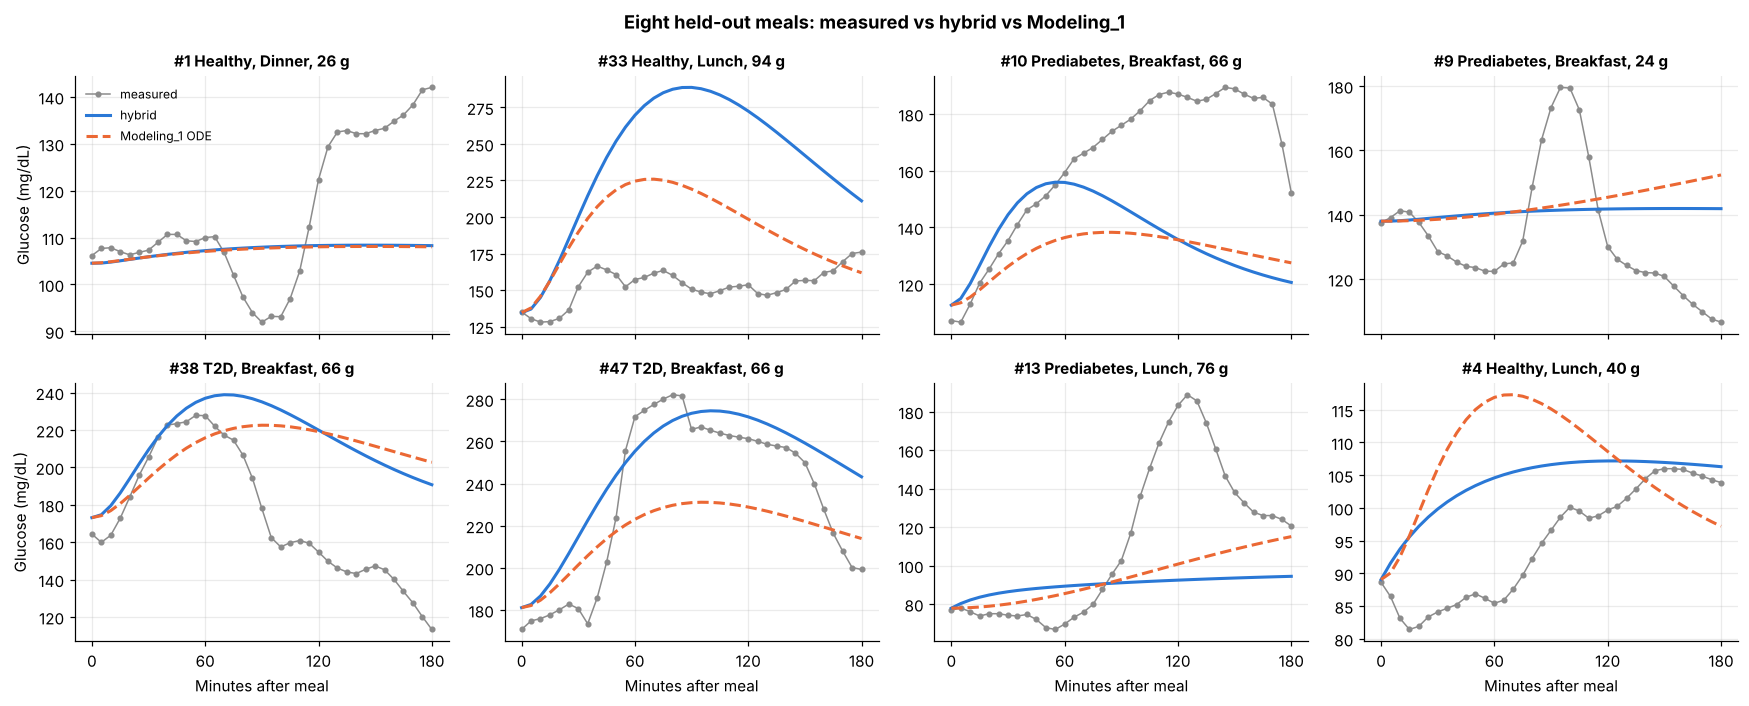

In [16]:
# A few test meals: measured vs hybrid vs Modeling_1, two per group plus two more
rng = np.random.default_rng(3)
pick = []
for g in GROUP_ORDER:
    idx = np.flatnonzero((test.group == g).values)
    pick += list(rng.choice(idx, 2, replace=False))
pick += list(rng.choice(np.setdiff1d(np.arange(len(test)), pick), 2, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for ax, i in zip(axes.ravel(), pick):
    r = test.iloc[i]
    ax.plot(GRID, r.obs, "o-", color=C_MEASURED, ms=3, lw=1, label="measured")
    ax.plot(GRID, pred_hybrid[i], color=C_HYBRID, label="hybrid")
    ax.plot(GRID, pred_m1[i], color=C_ODE, ls="--", label="Modeling_1 ODE")
    ax.set_title(f"#{r.sid} {r.group}, {r.meal_type}, {r.carbs:.0f} g", fontsize=10)
    ax.set_xticks(range(0, 181, 60))
for ax in axes[1]: ax.set_xlabel("Minutes after meal")
for ax in axes[:, 0]: ax.set_ylabel("Glucose (mg/dL)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Eight held-out meals: measured vs hybrid vs Modeling_1", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading this:** these are randomly chosen meals, not the best ones. Where the response looks like a normal single meal (for example #38, #47), the hybrid tracks the rise better than `Modeling_1`. The big misses fall into two kinds no meal model can fix: a **second rise** long after the meal (#1, #9, #13), which points to something eaten and not logged; and **logged carbs that never show up** (#33, a 94 g lunch with almost no rise), where the log or the meal itself was off. These are the unrecorded factors from EDA section 10, and they set a floor on how good any model can look on this data.

## 9. What did the network learn?

Because the network only sets physical quantities, we can ask it directly. We take a **typical lunch** (median carbs, fat, protein and fiber of training lunches, at 12:30, steady glucose at the resting level) and change one input at a time.

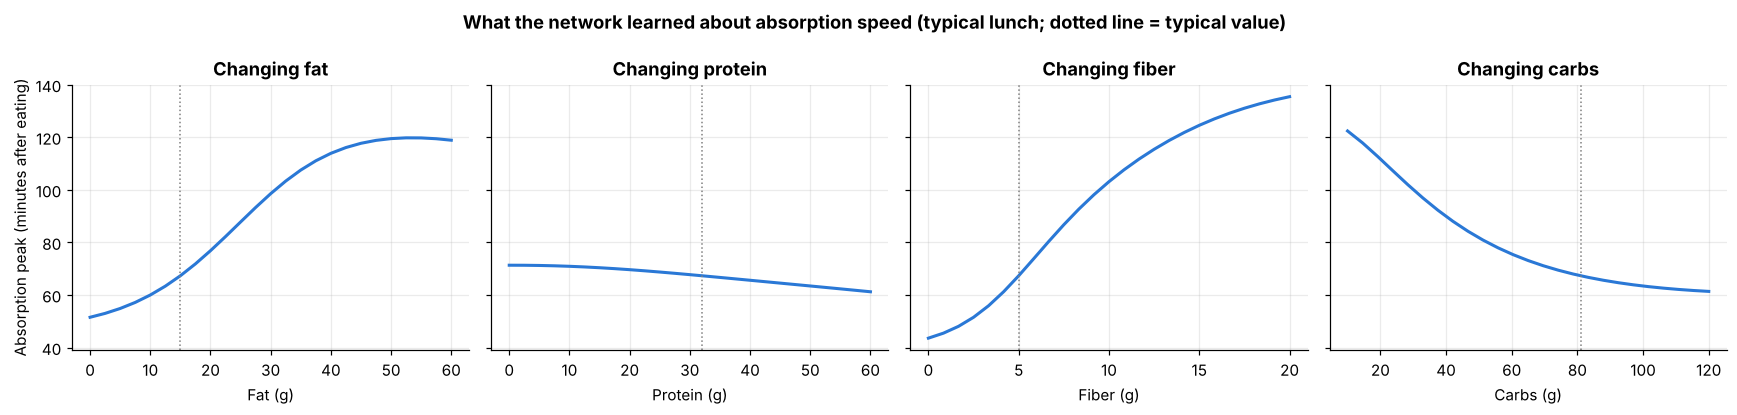

In [17]:
lunches = train[train.meal_type == "Lunch"]
typical = dict(carbs=lunches.carbs.median(), fat=lunches.fat.median(), protein=lunches.protein.median(),
               fiber=lunches.fiber.median(), hour=12.5, pre_change_60=0.0, above_resting=0.0, meal_type="Lunch")
ka_pop = float(torch.exp(hybrid.pop.detach().cpu()[0]))

def network_outputs(rows):
    df = pd.DataFrame(rows)
    X = torch.tensor(((meal_features(df) - FEAT_MEAN) / FEAT_SD).values, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        ka_mult, carb_mult, settle, _ = (t.cpu() if torch.is_tensor(t) else t for t in hybrid.meal_terms(X))
    return pd.DataFrame({"absorption_peak_min": 1 / (ka_pop * ka_mult.numpy()), "carb_mult": carb_mult.numpy(), "settle": settle.numpy()})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (feat, values, label) in zip(axes, [("fat", np.linspace(0, 60, 25), "Fat (g)"), ("protein", np.linspace(0, 60, 25), "Protein (g)"),
                                            ("fiber", np.linspace(0, 20, 25), "Fiber (g)"), ("carbs", np.linspace(10, 120, 25), "Carbs (g)")]):
    out = network_outputs([{**typical, feat: v} for v in values])
    ax.plot(values, out.absorption_peak_min, color=C_HYBRID)
    ax.axvline(typical[feat], color="gray", ls=":", lw=1)
    ax.set(xlabel=label, title=f"Changing {label.split(' ')[0].lower()}")
axes[0].set_ylabel("Absorption peak (minutes after eating)")
fig.suptitle("What the network learned about absorption speed (typical lunch; dotted line = typical value)", fontweight="bold")
plt.tight_layout(); plt.show()

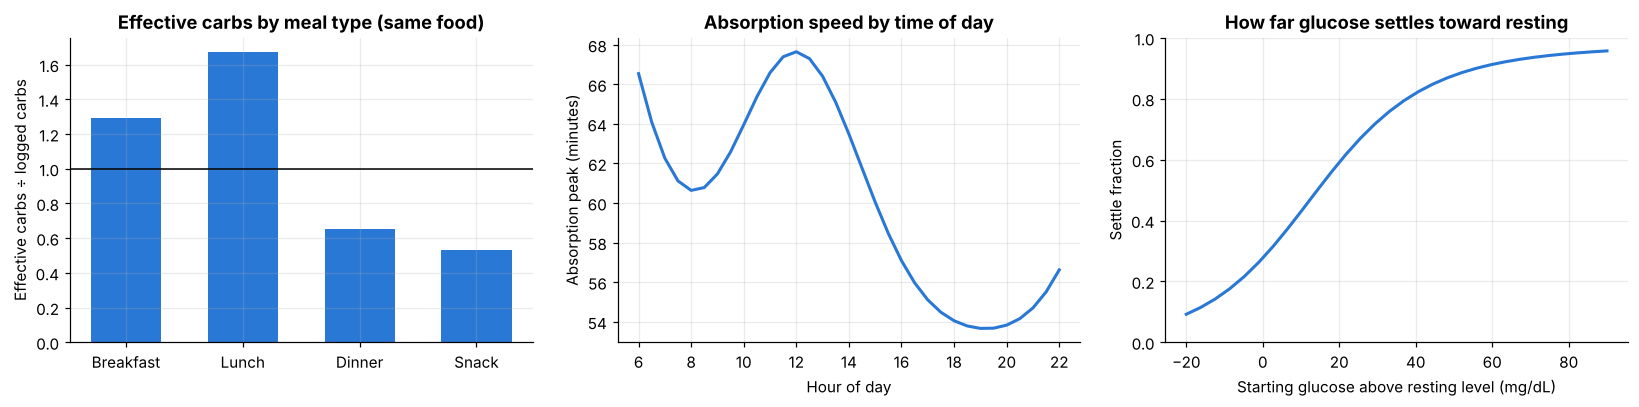

Across test meals, the network's adjustments ranged:


,absorption multiplier,effective carbs,settle fraction
10%,0.55,0.62,0.02
50%,1.09,0.98,0.20
90%,1.78,1.52,0.89


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
by_type = network_outputs([{**typical, "meal_type": t, "hour": h} for t, h in zip(MEAL_TYPES, [8.0, 12.5, 19.0, 15.5])])
axes[0].bar(MEAL_TYPES, by_type.carb_mult, color=C_HYBRID, width=0.6)
axes[0].axhline(1, color="black", lw=1)
axes[0].set(ylabel="Effective carbs ÷ logged carbs", title="Effective carbs by meal type (same food)")

hours = np.linspace(6, 22, 33)
out_h = network_outputs([{**typical, "hour": h} for h in hours])
axes[1].plot(hours, out_h.absorption_peak_min, color=C_HYBRID)
axes[1].set(xlabel="Hour of day", ylabel="Absorption peak (minutes)", title="Absorption speed by time of day")

above = np.linspace(-20, 90, 30)
out_a = network_outputs([{**typical, "above_resting": a} for a in above])
axes[2].plot(above, out_a.settle, color=C_HYBRID)
axes[2].set(xlabel="Starting glucose above resting level (mg/dL)", ylabel="Settle fraction",
            title="How far glucose settles toward resting", ylim=(0, 1))
plt.tight_layout(); plt.show()

print("Across test meals, the network's adjustments ranged:")
pd.DataFrame({"absorption multiplier": extra_test["ka_mult"], "effective carbs": extra_test["carb_mult"],
              "settle fraction": extra_test["settle"]}).describe(percentiles=[0.1, 0.5, 0.9]).loc[["10%", "50%", "90%"]].round(2)

**Reading these:** each curve shows how one input moves a physical quantity when everything else is a typical lunch.

What matches known physiology, a good sign the network learned something real:
- **Fat and fiber slow absorption a lot:** the absorption peak moves from about 50 minutes for a lean, low-fiber meal to about 120–135 minutes for a high-fat or high-fiber one. Both are well known to slow stomach emptying.
- **Meals that start further above the resting level settle further toward it** (settle fraction rising from about 0.1 to about 0.95). That's exactly the dip behavior `Modeling_1` couldn't produce.

What needs caution:
- **Protein** barely changes absorption here.
- **Bigger carb portions are absorbed *faster*** in the model, which isn't the textbook expectation. It may reflect what big meals were in this study (the standardized breakfast and lunch) rather than carb size itself.
- **Effective carbs differ a lot by meal type:** the same food counts as about 1.3–1.7× its logged carbs at breakfast and lunch, but only about 0.5–0.65× at dinner and for snacks. Breakfast and lunch were largely standardized, while dinners and snacks were self-logged, so this most likely reflects **how accurately carbs were logged**, not a real breakfast-versus-dinner difference. Lunch sits near the network's upper limit (×2).
- **Time of day** changes absorption only slightly (about 54–68 minutes).

Treat all of these as what the model *uses*, not proof of physiology: inputs are correlated in real meals (big meals tend to have more fat and protein), and the macros are estimates.

## 10. A brand-new person (no calibration)

As in `Modeling_1` section 8, but done properly for a model with a learned network: **5-fold cross-validation by person.** Each fold trains the hybrid on 80% of the people, then predicts the other 20% using only the **population average** person parameters (plus each meal's own network adjustments). Held-out people contribute nothing to their own predictions.

Compared with `Modeling_1`'s population ODE (the median of everyone else's fitted parameters) and with the personalized hybrid from section 8.

In [19]:
folds = np.array_split(np.random.default_rng(SEED).permutation(SIDS), 5)
pop_rows = []
for k, held in enumerate(folds):
    held = set(held)
    tr_k, va_k = train[~train.sid.isin(held)], val[~val.sid.isin(held)]
    te_k = test[test.sid.isin(held)]
    torch.manual_seed(SEED)
    m_k = HybridGlucose(INIT_LOGP, **VERSIONS[CHOSEN]).to(DEVICE)
    train_hybrid(m_k, to_tensors(tr_k), to_tensors(va_k), label=f"fold {k + 1} (held out {len(held)} people)")
    d_k = to_tensors(te_k)
    pred_k, _ = predict(m_k, d_k, person_logp=m_k.pop.detach().repeat(len(te_k), 1))
    pop_rows += score_rows(pred_k, te_k, "Hybrid, population (no calibration)")
    for sid, g in te_k.groupby("sid"):
        others = np.log(m1_params.drop(index=sid)[["ka", "SG", "SI"]]).median().values
        pop_rows += score_rows(simulate_np(*np.exp(others), g.carbs.values, g.Gb.values, g.alpha.values), g,
                               "Modeling_1 ODE, population (no calibration)")

new_person = pd.concat([pd.DataFrame(pop_rows), scores[scores.model.isin([HYB, "Modeling_1 ODE"])]])
np_order = ["Modeling_1 ODE, population (no calibration)", "Hybrid, population (no calibration)", "Modeling_1 ODE", HYB]
print("Median error on test meals:")
display(new_person.groupby("model")[cols].median().reindex(np_order).round(1))
new_person.pivot_table(index="model", columns="group", values="rmse", aggfunc="median").reindex(index=np_order, columns=GROUP_ORDER).round(1)

fold 1 (held out 8 people)                    best validation RMSE  29.7 (epoch 147) | 30s


fold 2 (held out 7 people)                    best validation RMSE  28.5 (epoch 147) | 31s


fold 3 (held out 7 people)                    best validation RMSE  29.1 (epoch 178) | 31s


fold 4 (held out 7 people)                    best validation RMSE  28.4 (epoch 160) | 31s


fold 5 (held out 7 people)                    best validation RMSE  29.2 (epoch 114) | 31s
Median error on test meals:


,rmse,peak_err,tpeak_err,bias
model,,,,
"Modeling_1 ODE, population (no calibration)",27.9,23.8,30.0,9.4
"Hybrid, population (no calibration)",25.0,23.2,35.0,2.6
Modeling_1 ODE,23.9,23.1,30.0,3.1
Hybrid (C),22.4,20.8,30.0,5.2


group,Healthy,Prediabetes,T2D
model,,,
"Modeling_1 ODE, population (no calibration)",24.4,26.4,32.5
"Hybrid, population (no calibration)",21.5,25.1,28.0
Modeling_1 ODE,16.4,23.7,30.8
Hybrid (C),16.2,23.6,27.8


## 11. Do the hybrid's person parameters still reflect metabolic health?

The network now handles meal-to-meal variation, so each person's SG should be a cleaner measure of their own glucose clearance. Same check as `Modeling_1` section 9, with HbA1c as a continuous value.

In [20]:
hp = pd.DataFrame(torch.exp(hybrid.person.detach().cpu()).numpy(), index=SIDS, columns=["ka", "SG", "SI", "carb_level"])
hp = hp.join(flags[["group", "A1c", "groups_agree", "cycle_status"]])
if not VERSIONS[CHOSEN].get("person_carbs"):
    hp = hp.drop(columns="carb_level")

def rho_table(df, label):
    out = {}
    for p in [c for c in ["ka", "SG", "SI", "carb_level"] if c in df]:
        r, pv = spearmanr(df[p], df["A1c"])
        out[p] = {"rho": r, "p": pv}
    return pd.DataFrame(out).T.add_prefix(label + ": ")

pd.concat([rho_table(m1_params, "Modeling_1"), rho_table(hp, "hybrid, all"),
           rho_table(hp[hp.groups_agree], "hybrid, labels agree"),
           rho_table(hp[hp.cycle_status != "<45: likely cycling"], "hybrid, no women <45")], axis=1).round(3)

,Modeling_1: rho,Modeling_1: p,"hybrid, all: rho","hybrid, all: p","hybrid, labels agree: rho","hybrid, labels agree: p","hybrid, no women <45: rho","hybrid, no women <45: p"
ka,-0.003,0.986,0.197,0.248,0.225,0.270,0.208,0.260
SG,-0.611,0.000,-0.716,0.000,-0.750,0.000,-0.678,0.000
SI,-0.555,0.000,-0.195,0.254,-0.266,0.188,-0.110,0.556


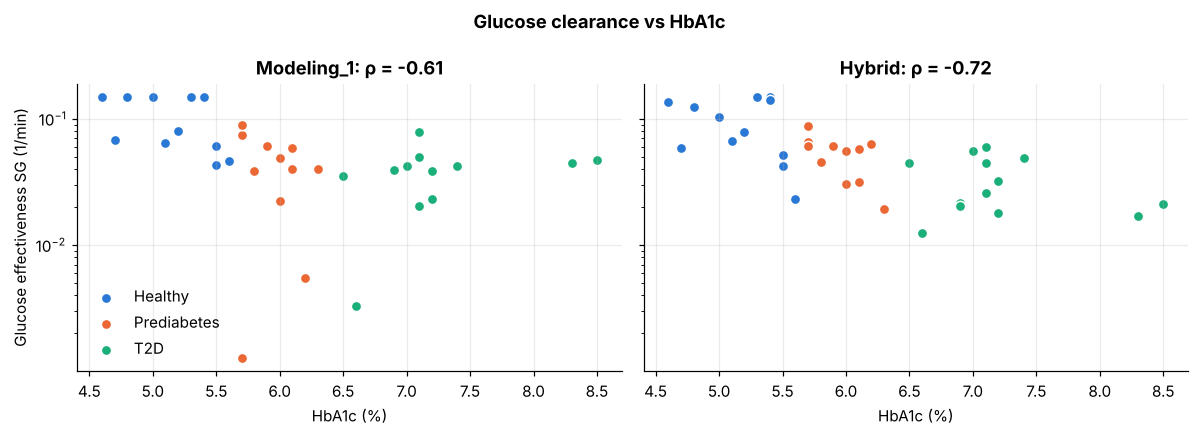

Median person parameters by group (hybrid):


,ka,SG,SI
group,,,
Healthy,0.013664,0.090634,0.000001
Prediabetes,0.015002,0.057538,0.000001
T2D,0.015815,0.025695,0.000001


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (df, title) in zip(axes, [(m1_params, "Modeling_1"), (hp, "Hybrid")]):
    for g in GROUP_ORDER:
        d = df[df.group == g]
        ax.scatter(d["A1c"], d["SG"], color=GROUP_COLORS[g], edgecolor="white", s=45, label=g)
    ax.set(yscale="log", xlabel="HbA1c (%)", title=f"{title}: ρ = {spearmanr(df['SG'], df['A1c'])[0]:.2f}")
axes[0].set_ylabel("Glucose effectiveness SG (1/min)")
axes[0].legend(frameon=False)
fig.suptitle("Glucose clearance vs HbA1c", fontweight="bold")
plt.tight_layout(); plt.show()
print("Median person parameters by group (hybrid):")
hp.groupby("group")[["ka", "SG", "SI"]].median().reindex(GROUP_ORDER)

## 12. Save results

In [22]:
scores.to_csv(P / "pinn_test_scores.csv", index=False)
new_person.to_csv(P / "pinn_new_person_scores.csv", index=False)
hp.rename_axis("sid").to_csv(P / "pinn_person_params.csv")
torch.save({"state_dict": {k: v.cpu() for k, v in hybrid.state_dict().items()}, "version": CHOSEN, "config": VERSIONS[CHOSEN],
            "feat_mean": {k: float(v) for k, v in FEAT_MEAN.items()}, "feat_sd": {k: float(v) for k, v in FEAT_SD.items()},
            "sids": [int(s) for s in SIDS]}, P / "pinn_hybrid_model.pt")
print("Saved pinn_test_scores.csv, pinn_new_person_scores.csv, pinn_person_params.csv and pinn_hybrid_model.pt to", P)
# Reload later with: torch.load(P / "pinn_hybrid_model.pt")  (plain Python numbers, so the safe default loader works)

Saved pinn_test_scores.csv, pinn_new_person_scores.csv, pinn_person_params.csv and pinn_hybrid_model.pt to processed/


## 13. What we learned

Results are based on 36 people (463 training, 134 validation and 234 test meals). The run is seeded and reproducible.

**Part A: the classic PINN**
- On a synthetic meal it fitted the curve to within about 1 mg/dL of the truth and recovered absorption speed, but split clearance wrongly between SG and SI. That's the same identifiability problem as before: one meal can't separate them.
- It took about 24 seconds for one meal, against 0.1 seconds for a direct ODE fit.
- On a real meal with an unlogged second rise, it fitted the data almost perfectly by **breaking the physics** (residual about 80× higher than on synthetic data). A soft physics penalty lets a flexible network explain anything, so the physics residual is worth monitoring as a warning sign.

**Part B: the hybrid model**
- **Chosen on validation meals:** version C (meal network + settle toward resting). Validation RMSE fell from 40.2 (physics only) to 34.4 (+ settle) to 28.4 (+ meal network); the extra flexibility in D didn't help.
- **On held-out meals it's the best model so far:** median RMSE 22.4 mg/dL, vs 23.3 for the best simple baseline and 23.9 for `Modeling_1`. Peak-height error is 20.8 (`Modeling_1`: 23.1).
- **The gains are real against the physics-only models** (95% intervals exclude zero): 1.7 mg/dL better than `Modeling_1` (CI 0.1 to 3.2) and 1.0 better than the same physics retrained here (CI 0.3 to 2.6).
- **Against the simple baseline it's better but not conclusively:** 1.2 lower (CI from 3.0 lower to 0.3 higher).
- **The biggest gain is T2D:** median RMSE 27.8, vs 30.8 for `Modeling_1` (4.3 better, CI 1.4 to 8.2) and 30.4 for the baseline. This was the group `Modeling_1` handled worst.
- **New people, with no calibration:** 25.0 mg/dL vs 27.9 for `Modeling_1`'s population model, about 10% better. Personalization still helps (25.0 → 22.4), but the gap is smaller, because the network transfers meal knowledge between people.
- **The parameters became more meaningful.** Glucose clearance SG tracks HbA1c at ρ = −0.72 (−0.75 when labels agree; −0.68 without women under 45), and the three groups now separate cleanly: median SG about 0.091 (healthy), 0.058 (prediabetes) and 0.026 (T2D).
- **The network learned physiologically sensible rules:** fat and fiber slow absorption (peak about 50 → 120+ minutes), and meals that start above the resting level settle back toward it. Its effective-carbs pattern by meal type most likely reflects how accurately each meal type was logged.

**What still isn't solved**
- **Peak timing:** still a median 30 minutes off, vs 25 for the baseline. Absorption now varies by meal, but timing of real peaks is noisy and often distorted by unlogged eating.
- **Slight over-prediction** (bias +5 mg/dL).
- **Insulin sensitivity** went to its lower limit for everyone, so all clearance is carried by SG. Without insulin data, it remains unidentifiable.
- **Unlogged eating** (second rises) and **carbs that never show up** set a floor that no meal model can get below on this data.

**Possible next steps:** add an "unexplained input" term so second rises don't distort fitting; repeat training with several random seeds to measure stability; and test the model on a second dataset (for example BIG IDEAs) to check it generalizes beyond CGMacros.
